## Imports

In [68]:
from pathlib import Path
import json
import pickle
import random
import math
import copy

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from tokenizers import Tokenizer
import matplotlib.pyplot as plt
import pandas as pd

### load preprocessing files

In [69]:
PROJECT_DIR = Path.cwd().parent

PROCESSED_DIR = PROJECT_DIR/"data"/"processed"
MODEL_DIR = PROJECT_DIR/"models"/"lstm"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

hf_tokenizer = Tokenizer.from_file(str(PROCESSED_DIR/"tokenizer.json"))

with open(PROCESSED_DIR/"encoded_lines.pkl", "rb") as f:
    encoded_lines = pickle.load(f)

with open(PROCESSED_DIR/"vocab.json", "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

word_to_id = vocab_data["word_to_id"]
id_to_word = {int(idx): word for word, idx in word_to_id.items()}

vocab_size = len(word_to_id)

bos_id = word_to_id["<bos>"]
eos_id = word_to_id["<eos>"]
unk_id = word_to_id["<unk>"]
pad_id = word_to_id["<pad>"]

print("Vocabulary size:", vocab_size)

for split, sequences in encoded_lines.items():
    print(split, "sequences:", len(sequences))

Vocabulary size: 46165
test sequences: 2185
train sequences: 17556
validation sequences: 1841


---

## Training

### settings

In [70]:
# reproducibility
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# model settings
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
NUM_LAYERS = 1
DROPOUT = 0.2

# memory-conscious sequence settings
BLOCK_SIZE = 32
BATCH_SIZE = 4

# training settings
LEARNING_RATE = 0.001
EPOCHS = 10

print("Block size:", BLOCK_SIZE)
print("Batch size:", BATCH_SIZE)

Using device: cuda
Block size: 32
Batch size: 4


block size means the LSTM processes up to 32 input tokens in each training example.   
and cuz batch size is 4, it processes four examples at once.

### Making the dataset ready

In [71]:
def make_lstm_dataset(sequences, block_size, pad_id):
    input_blocks = []
    target_blocks = []

    for sequence in sequences:
        # input and target are shifted by one token.
        for start in range(0, len(sequence) - 1, block_size):
            
            end = min(start + block_size, len(sequence) - 1) # never letting the input include the very last token of the sequence
            
            # input and target are shifted  by one position
            x = sequence[start:end]
            y = sequence[start + 1: end + 1]
            
            # adding padding, to make the blocks same length
            x = x + [pad_id]*(block_size - len(x))
            y = y + [pad_id]*(block_size - len(y))

            input_blocks.append(x)
            target_blocks.append(y)
            
    # converting to tensor
    inputs = torch.tensor(input_blocks, dtype=torch.long)
    targets = torch.tensor(target_blocks, dtype=torch.long)

    return TensorDataset(inputs, targets)

In [72]:
# for each split
train_dataset = make_lstm_dataset(encoded_lines["train"], BLOCK_SIZE, pad_id)
validation_dataset = make_lstm_dataset(encoded_lines["validation"], BLOCK_SIZE, pad_id)
test_dataset = make_lstm_dataset(encoded_lines["test"], BLOCK_SIZE, pad_id)

print("Training blocks:", len(train_dataset))
print("Validation blocks:", len(validation_dataset))
print("Test blocks:", len(test_dataset))

# we only shuffle training blocks
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# one example
x_example, y_example = train_dataset[0]

print("\nInput ids:", x_example[:10].tolist())
print("Target ids:", y_example[:10].tolist())

Training blocks: 70766
Validation blocks: 7386
Test blocks: 8390

Input ids: [2, 21646, 119, 3840, 152, 44, 1, 4345, 23, 749]
Target ids: [21646, 119, 3840, 152, 44, 1, 4345, 23, 749, 44]


### Defining the lstm

In [73]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers=1, dropout=0.2, pad_id=0):
        super().__init__()
        
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_id) # first embeddings
        self.lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_dim, num_layers=num_layers, batch_first=True, dropout=dropout if num_layers > 1 else 0.0) # then learning patterns across the sequence
        self.dropout = nn.Dropout(dropout) # to reduce overfitting during training
        
        # score for every possible next token
        self.output = nn.Linear(hidden_dim, vocab_size)
        
    def forward(self, input_ids):
        embedded = self.embedding(input_ids) # [batch_size, sequence_length, embedding_dim]
        lstm_output, _ = self.lstm(embedded) # [batch_size, sequence_length, hidden_dim]
        lstm_output = self.dropout(lstm_output) 
        logits = self.output(lstm_output)
        
        return logits

### Initialize the model and loss function

In [74]:
model = LSTMLanguageModel(vocab_size=vocab_size, embedding_dim=EMBEDDING_DIM, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS, dropout=DROPOUT, pad_id=pad_id).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=pad_id, reduction="sum") # ignoring padded targets when calculating loss
optimizer = torch.optim.Adam(model.parameters(), lr= LEARNING_RATE)

number_of_parameters = sum(parameter.numel() for parameter in model.parameters())

print(f"Model parameters: {number_of_parameters:,}")

Model parameters: 11,996,501


---

## Training 

In [75]:
def run_epoch(model, data_loader, criterion, optimizer=None): # it is like if the we provide optimizer as an argument then the function will do training otherwise evaluation
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_tokens = 0

    for inputs, targets in data_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        valid_tokens = (targets != pad_id).sum()

        if valid_tokens.item() == 0:
            continue

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(inputs) # forward pass
            loss = criterion(logits.reshape(-1, vocab_size), targets.reshape(-1))

            if training:
                batch_average_loss = loss/valid_tokens
                batch_average_loss.backward()

                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # Gradient clipping
                optimizer.step()

        total_loss += loss.item()
        total_tokens += valid_tokens.item()

    if total_tokens == 0:
        raise ValueError("No valid target tokens found.")

    average_loss = total_loss/total_tokens
    perplexity = math.exp(min(average_loss, 20))

    return {
        "loss": average_loss,
        "perplexity": perplexity
    }

### training on data and monitoring

In [76]:
best_validation_perplexity = float("inf") # pos infinity
best_model_path = MODEL_DIR / "lstm_best.pt" # where we should save the best model
history = []

for epoch in range(1, EPOCHS + 1):

    # training
    train_results = run_epoch(model, train_loader, criterion, optimizer=optimizer)

    # evaluation
    validation_results = run_epoch(model, validation_loader, criterion)

    # then storing everything
    epoch_results = {
        "epoch": epoch,
        "train_loss": train_results["loss"],
        "train_perplexity": train_results["perplexity"],
        "validation_loss": validation_results["loss"],
        "validation_perplexity": validation_results["perplexity"]
    }

    history.append(epoch_results)

    ## printing everything
    print(f"\nEpoch {epoch}/{EPOCHS}")
    print(f"Train loss: {train_results['loss']:.4f}")
    print(f"Validation loss: {validation_results['loss']:.4f}")
    print(f"Train perplexity: {train_results['perplexity']:.4f}")
    print(f"Validation perplexity: "
          f"{validation_results['perplexity']:.4f}")

    # we only save the model if it is the best so far
    if validation_results["perplexity"] < best_validation_perplexity:
        best_validation_perplexity = validation_results["perplexity"]

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_validation_perplexity": best_validation_perplexity,
                "embedding_dim": EMBEDDING_DIM,
                "hidden_dim": HIDDEN_DIM,
                "num_layers": NUM_LAYERS,
                "dropout": DROPOUT,
                "vocab_size": vocab_size,
                "pad_id": pad_id
            }, best_model_path
        )

        print("-- New best checkpoint saved!")

    # then saving the history
    history_path = MODEL_DIR / "lstm_training_history.json"

    with open(history_path, "w", encoding="utf-8") as f:
        json.dump(history, f, indent=4)

print("\nTraining completed:)")
print("Best validation perplexity:", best_validation_perplexity)
print("Best checkpoint:", best_model_path)


Epoch 1/10
Train loss: 6.4708
Validation loss: 5.8399
Train perplexity: 646.0231
Validation perplexity: 343.7366
-- New best checkpoint saved!

Epoch 2/10
Train loss: 5.9262
Validation loss: 5.6703
Train perplexity: 374.7240
Validation perplexity: 290.1142
-- New best checkpoint saved!

Epoch 3/10
Train loss: 5.7146
Validation loss: 5.5961
Train perplexity: 303.2680
Validation perplexity: 269.3686
-- New best checkpoint saved!

Epoch 4/10
Train loss: 5.5753
Validation loss: 5.5559
Train perplexity: 263.8368
Validation perplexity: 258.7693
-- New best checkpoint saved!

Epoch 5/10
Train loss: 5.4747
Validation loss: 5.5362
Train perplexity: 238.5811
Validation perplexity: 253.7097
-- New best checkpoint saved!

Epoch 6/10
Train loss: 5.3935
Validation loss: 5.5206
Train perplexity: 219.9659
Validation perplexity: 249.7754
-- New best checkpoint saved!

Epoch 7/10
Train loss: 5.3299
Validation loss: 5.5175
Train perplexity: 206.4190
Validation perplexity: 249.0199
-- New best checkpoint

### Plotting

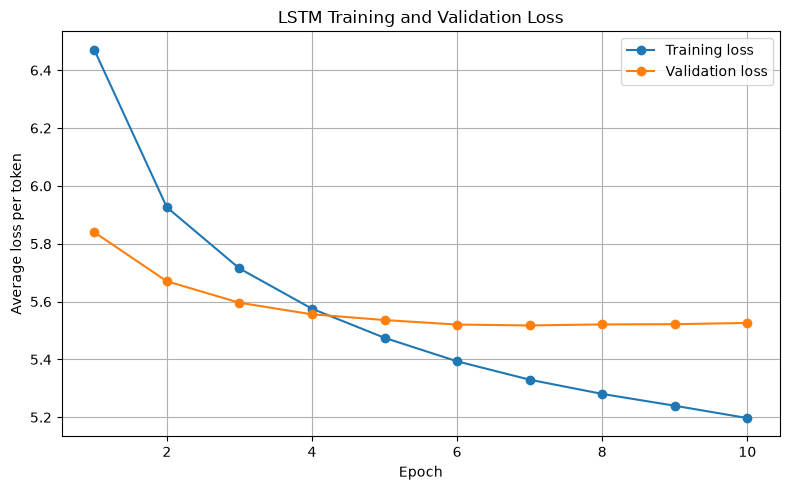

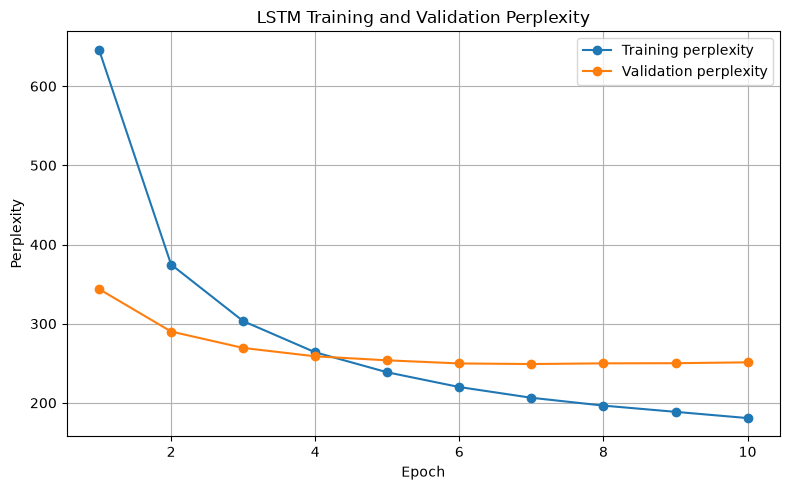

In [77]:
epochs = [item["epoch"] for item in history]
train_losses = [item["train_loss"] for item in history]
val_losses = [item["validation_loss"] for item in history]
train_perplexities = [item["train_perplexity"] for item in history]
val_perplexities = [item["validation_perplexity"] for item in history]

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker="o", label="Training loss")
plt.plot(epochs, val_losses, marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Average loss per token")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# plot perplexity
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_perplexities, marker="o", label="Training perplexity")
plt.plot(epochs, val_perplexities, marker="o", label="Validation perplexity")
plt.xlabel("Epoch")
plt.ylabel("Perplexity")
plt.title("LSTM Training and Validation Perplexity")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

the LSTM model's training loss and perplexity decrease consistently over 10 epochs, indicating that the model is learning patterns from the training data.   
Validation loss and perplexity also decrease initially, with validation perplexity dropping from approximately 344 to 249 by epoch 7.
However, after epoch 7, validation performance stabilizes and slightly worsens, while training performance continues to improve. This suggests mild overfitting, as the model becomes better at predicting training data without achieving further improvements on unseen data.

### Hyperparameter Tuning


~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Testing learning rate: 0.0003
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~

Epoch 1/10
Train loss: 6.7310
Validation loss: 6.0652
Train perplexity: 837.9803
Validation perplexity: 430.5882

Epoch 2/10
Train loss: 6.1844
Validation loss: 5.8785
Train perplexity: 485.1103
Validation perplexity: 357.2773

Epoch 3/10
Train loss: 5.9905
Validation loss: 5.7781
Train perplexity: 399.6248
Validation perplexity: 323.1542

Epoch 4/10
Train loss: 5.8641
Validation loss: 5.7086
Train perplexity: 352.1580
Validation perplexity: 301.4484

Epoch 5/10
Train loss: 5.7659
Validation loss: 5.6593
Train perplexity: 319.2324
Validation perplexity: 286.9496

Epoch 6/10
Train loss: 5.6831
Validation loss: 5.6185
Train perplexity: 293.8666
Validation perplexity: 275.4707

Epoch 7/10
Train loss: 5.6121
Validation loss: 5.5837
Train perplexity: 273.7154
Validation perplexity: 266.0461

Epoch 8/10
Train loss: 5.5503
Validation loss: 5.5609
Train perplexi

,learning_rate,best_epoch,best_validation_perplexity
0,0.0005,10,244.258022
1,0.0010,8,247.525746
2,0.0003,10,250.881437



Best learning rate: 0.0005
Best validation perplexity: 244.2580


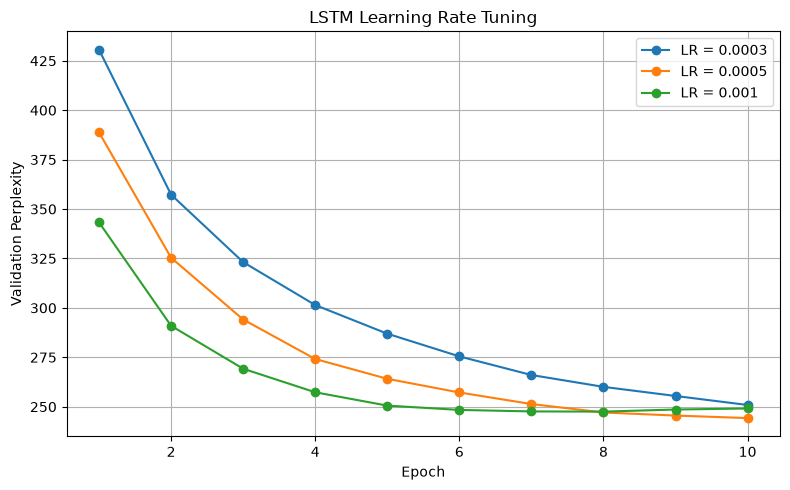

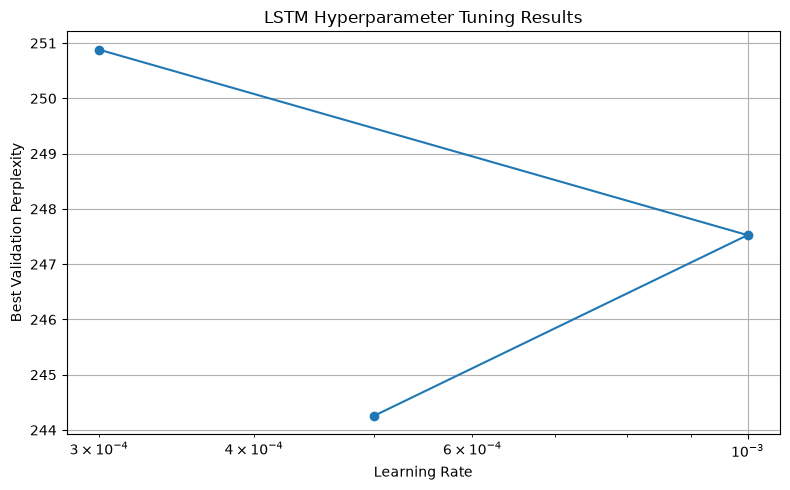


Hyperparameter tuning completed!
Best learning rate: 0.0005
Best validation perplexity: 244.2580


In [79]:
learning_rates = [0.0003, 0.0005, 0.001]
TUNING_EPOCHS = 10
tuning_results = []
tuning_history = {}

# just a function to create a fresh lstm model
def create_tuning_model():
    return LSTMLanguageModel(vocab_size=vocab_size, embedding_dim=EMBEDDING_DIM, hidden_dim=HIDDEN_DIM, num_layers=NUM_LAYERS, dropout=DROPOUT, pad_id=pad_id).to(device)

# to use identical initial weights for each learning rate
torch.manual_seed(42)

reference_model = create_tuning_model()
initial_weights = copy.deepcopy(reference_model.state_dict())

## testing different learning rates
for lr in learning_rates:

    print("\n" + "~" * 50)
    print(f"Testing learning rate: {lr}")
    print("~" * 50)

    tuning_model = create_tuning_model()
    tuning_model.load_state_dict(initial_weights)
    tuning_optimizer = torch.optim.Adam(tuning_model.parameters(), lr=lr)

    best_val_perplexity = float("inf")
    best_epoch = 0
    best_model_state = None

    current_history = []

    for epoch in range(1, TUNING_EPOCHS+1):

        train_results = run_epoch(tuning_model, train_loader, criterion, optimizer=tuning_optimizer)
        validation_results = run_epoch(tuning_model, validation_loader, criterion)

        epoch_results = {
            "epoch": epoch,
            "train_loss": train_results["loss"],
            "train_perplexity": train_results["perplexity"],
            "validation_loss": validation_results["loss"],
            "validation_perplexity": validation_results["perplexity"]
        }

        current_history.append(epoch_results)

        print(f"\nEpoch {epoch}/{TUNING_EPOCHS}")
        print(f"Train loss: {train_results['loss']:.4f}")
        print(f"Validation loss: {validation_results['loss']:.4f}")
        print(f"Train perplexity: {train_results['perplexity']:.4f}")
        print(f"Validation perplexity: "
             f"{validation_results['perplexity']:.4f}")

        if validation_results["perplexity"] < best_val_perplexity:
            best_val_perplexity = validation_results["perplexity"]
            best_epoch = epoch
            best_model_state = copy.deepcopy(tuning_model.state_dict())

    checkpoint_path = MODEL_DIR/f"lstm_tuning_lr_{lr}.pt"

    torch.save(
        {
            "model_state_dict": best_model_state,
            "learning_rate": lr,
            "best_epoch": best_epoch,
            "best_validation_perplexity": best_val_perplexity,
            "embedding_dim": EMBEDDING_DIM,
            "hidden_dim": HIDDEN_DIM,
            "num_layers": NUM_LAYERS,
            "dropout": DROPOUT,
            "vocab_size": vocab_size,
            "pad_id": pad_id
        }, checkpoint_path
    )

    tuning_results.append({
        "learning_rate": lr,
        "best_epoch": best_epoch,
        "best_validation_perplexity": best_val_perplexity
    })

    tuning_history[str(lr)] = current_history
    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation perplexity: {best_val_perplexity:.4f}")
    print(f"Checkpoint saved: {checkpoint_path}")

# compare hyperparameter tuning results
tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values(by="best_validation_perplexity").reset_index(drop=True)

print("\n" + "-" * 50)
print("Hyperparameter Tuning Results")
print("-" * 50)

display(tuning_df)

# best learning rate
best_lr = float(tuning_df.iloc[0]["learning_rate"])
best_ppl = float(tuning_df.iloc[0]["best_validation_perplexity"])

print(f"\nBest learning rate: {best_lr}")
print(f"Best validation perplexity: {best_ppl:.4f}")

tuning_df.to_csv(MODEL_DIR/"lstm_tuning_results.csv", index=False)

with open(MODEL_DIR/"lstm_tuning_history.json", "w", encoding="utf-8") as f:
    json.dump(tuning_history, f, indent=4)

## plotting
plt.figure(figsize=(8, 5))

for lr in learning_rates:
    results = tuning_history[str(lr)]
    epochs = [item["epoch"] for item in results]
    val_perplexities = [ item["validation_perplexity"] for item in results]

    plt.plot(epochs, val_perplexities, marker="o", label=f"LR = {lr}")

plt.xlabel("Epoch")
plt.ylabel("Validation Perplexity")
plt.title("LSTM Learning Rate Tuning")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(tuning_df["learning_rate"], tuning_df["best_validation_perplexity"], marker="o")

plt.xscale("log")
plt.xlabel("Learning Rate")
plt.ylabel("Best Validation Perplexity")
plt.title("LSTM Hyperparameter Tuning Results")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nHyperparameter tuning completed!")
print(f"Best learning rate: {best_lr}")
print(f"Best validation perplexity: {best_ppl:.4f}")

Learning rate tuning was performed using values of 0.0003, 0.0005, and 0.001 over 10 epochs. All three configurations showed decreasing validation perplexity, indicating improved model performance during training.
The learning rate of 0.0005 achieved the lowest validation perplexity of 244.26 at epoch 10, followed by 0.001 with 247.53 at epoch 8 and 0.0003 with 250.88 at epoch 10.   
Although 0.001 converged faster initially, its validation perplexity began increasing after epoch 8, suggesting mild overfitting. In contrast, 0.0005 showed consistent improvement throughout training.

### Loading the best tuned lstm model

In [80]:
best_tuned_path = MODEL_DIR/"lstm_tuning_lr_0.0005.pt"

checkpoint = torch.load(best_tuned_path, map_location=device, weights_only=True)

# a separate model for the tuned version
tuned_model = LSTMLanguageModel(vocab_size=checkpoint["vocab_size"], embedding_dim=checkpoint["embedding_dim"], hidden_dim=checkpoint["hidden_dim"], num_layers=checkpoint["num_layers"], dropout=checkpoint["dropout"], pad_id=checkpoint["pad_id"]).to(device)

# the best learned weights
tuned_model.load_state_dict(checkpoint["model_state_dict"])

tuned_model.eval()

print("Tuned LSTM loaded successfully!")
print("Learning rate:", checkpoint["learning_rate"])
print("Best epoch:", checkpoint["best_epoch"])
print("Best validation perplexity:", checkpoint["best_validation_perplexity"])

Tuned LSTM loaded successfully!
Learning rate: 0.0005
Best epoch: 10
Best validation perplexity: 244.25802183742462


## Evaluation

### top 1 and top 5 accuracy

I try to do same evaluation as I did for n-gram to compare them better

In [81]:
def evaluate_lstm_model(model, sequences, top_k=5):

    total_loss = 0.0
    total_predictions = 0
    unk_count = 0
    known_count = 0
    correct_top1 = 0
    correct_topk = 0

    special_ids = {bos_id, eos_id, pad_id, unk_id}

    model.eval()

    with torch.no_grad():
        for sequence in sequences:

            if len(sequence) < 2:
                continue

            input_ids = sequence[:-1]
            target_ids = sequence[1:]

            inputs = torch.tensor([input_ids], dtype=torch.long, device=device)
            logits = model(inputs)[0]
            log_probs = torch.log_softmax(logits, dim=-1)

            for i, target in enumerate(target_ids):

                if target == unk_id:
                    unk_count += 1
                else:
                    known_count += 1

                total_loss -= log_probs[i, target].item()
                total_predictions += 1

                if target != unk_id:
                    scores = logits[i].clone()

                    for special_id in special_ids:
                        scores[special_id] = float("-inf")

                    k = min(top_k, scores.numel() - len(special_ids))

                    predictions = torch.topk(scores, k=k).indices.tolist()

                    if predictions and target == predictions[0]:
                        correct_top1 += 1

                    if target in predictions:
                        correct_topk += 1

    if total_predictions == 0:
        raise ValueError("No valid predictions found.")

    perplexity = math.exp(total_loss / total_predictions)
    top1_accuracy = (correct_top1 / known_count if known_count else 0.0)
    topk_accuracy = (correct_topk / known_count if known_count else 0.0)

    unk_rate = unk_count/total_predictions

    return {
        "perplexity": perplexity,
        "top1_accuracy": top1_accuracy,
        f"top{top_k}_accuracy": topk_accuracy,
        "unk_rate": unk_rate,
        "number_of_predictions": total_predictions
    }


validation_results = evaluate_lstm_model(tuned_model, encoded_lines["validation"], top_k=5)
test_results = evaluate_lstm_model(tuned_model, encoded_lines["test"], top_k=5)

print("Final LSTM model results:")
print("=" * 55)
print("Learning rate:", checkpoint["learning_rate"])
print("Best epoch:", checkpoint["best_epoch"])
print("Vocabulary size:", vocab_size)
print("\n{:<25} {:>12} {:>12}".format("Metric", "Validation", "Test"))
print("-" * 55)

for metric in validation_results:
    val = validation_results[metric]
    test = test_results[metric]

    if "accuracy" in metric or metric == "unk_rate":
        val_str = f"{val:.2%}"
        test_str = f"{test:.2%}"

    elif metric == "number_of_predictions":
        val_str = str(val)
        test_str = str(test)

    else:
        val_str = f"{val:.4f}"
        test_str = f"{test:.4f}"

    print(f"{metric:<25} {val_str:>12} {test_str:>12}")


Final LSTM model results:
Learning rate: 0.0005
Best epoch: 10
Vocabulary size: 46165

Metric                      Validation         Test
-------------------------------------------------------
perplexity                    233.4809     224.0379
top1_accuracy                   21.32%       21.58%
top5_accuracy                   39.22%       39.64%
unk_rate                         5.38%        5.96%
number_of_predictions           206188       232065


The best tuned LSTM model, using a learning rate of 0.0005 and the checkpoint from epoch 10, achieved a validation perplexity of 233.48 and a test perplexity of 224.04. The model also achieved a test Top-1 accuracy of 21.58% and a Top-5 accuracy of 39.64%, indicating that the correct next token appeared among the five highest-ranked suggestions in approximately 40% of eligible test cases.
Compared with the n-gram baseline, the LSTM achieved lower perplexity and higher prediction accuracy, suggesting that it learned useful sequential patterns for next-word prediction. The similar validation and test results also indicate reasonably consistent performance across the two datasets.

## examples from the test set

In [82]:
# to generate top k next word suggestions
def get_lstm_suggestions(prefix_ids, model, top_k=5):

    prefix_ids = prefix_ids[-BLOCK_SIZE:] # so same length as training

    if len(prefix_ids) == 0: # empty input in case
        raise ValueError("Prefix cannot be empty.")

    input_tensor = torch.tensor([prefix_ids], dtype=torch.long, device=device)
    model.eval()

    with torch.no_grad():

        logits = model(input_tensor)
        # taking predictions from the last position
        next_token_logits = logits[0, -1].clone() # scores for the next token

        special_ids = {bos_id, eos_id, pad_id, unk_id} # to exclude special tokens
        for token_id in special_ids:
            next_token_logits[token_id] = float("-inf") # so they can never appear in top

        # top k predictions
        k = min(top_k, next_token_logits.numel() - len(special_ids)) # how many predictions to return
        candidate_ids = torch.topk(next_token_logits, k=k).indices.tolist()

    return candidate_ids

In [83]:
def show_test_examples(sequences, model, number_of_examples=8, seed=42):

    rng = random.Random(seed)
    candidates = [] # to store the locations of valid next word prediction examples

    for sequence_index, sequence in enumerate(sequences):
        for target_position in range(3, len(sequence)): # possible target positions, and at least 3 preceding tokens as context

            target_id = sequence[target_position] # token id at the selected position
            if target_id in {bos_id, eos_id, pad_id, unk_id}:
                continue # to skip
            candidates.append((sequence_index, target_position))

    selected = rng.sample(candidates, k=min(number_of_examples, len(candidates))) # selecting without replacement

    for example_number, (sequence_index, target_position) in enumerate(selected, start=1): # to process each randomly selected example
        sequence = sequences[sequence_index] # getting the selected sequence
        prefix_ids = sequence[:target_position]
        actual_next_id = sequence[target_position]

        # the last 8 prefix tokens
        visible_prefix_ids = prefix_ids[-8:]

        prefix_text = " ".join(id_to_word[token_id] for token_id in visible_prefix_ids)
        actual_next_word = id_to_word[actual_next_id]

        # predictions from the model
        suggestion_ids = get_lstm_suggestions(prefix_ids, model, top_k=5)

        suggestions = [id_to_word[token_id] for token_id in suggestion_ids]

        # Check if the correct token is among top 5
        correct_top5 = actual_next_id in suggestion_ids

        print(f"\nExample {example_number}")
        print("Prefix: ", prefix_text)
        print("Correct word:", actual_next_word)
        print("Suggestions: ", ", ".join(suggestions))
        print("Correct word in top 5:", correct_top5)



print("========== Best Tuned lstm ==========")
show_test_examples(encoded_lines["test"], tuned_model, number_of_examples=8, seed=42)

========== Best Tuned lstm ==========

Example 1
Prefix:  for the The New York Dramatic Mirror found
Correct word: the
Suggestions:  the, that, a, it, in
Correct word in top 5: True

Example 2
Prefix:  three chief characteristics : a <unk> hull ,
Correct word: steam
Suggestions:  and, the, a, which, with
Correct word in top 5: False

Example 3
Prefix:  2013 . It peaked at number 13 in
Correct word: its
Suggestions:  the, a, its, an, Japan
Correct word in top 5: True

Example 4
Prefix:  and memorials . It also began the task
Correct word: of
Suggestions:  of, for, in, and, ,
Correct word in top 5: True

Example 5
Prefix:  Most Valuable Player award . <unk> was the
Correct word: first
Suggestions:  first, second, only, third, highest
Correct word in top 5: True

Example 6
Prefix:  <unk> , Christina <unk> 's posthumous <unk> Works
Correct word: ,
Suggestions:  ", ,, ., and, to
Correct word in top 5: True

Example 7
Prefix:  ( 153 km / h ) and tops
Correct word: out
Suggestions:  ,, ., of,